# Audio model + ACSR

In [1]:
import os
import sys
import json
import time
import re
import math
import tempfile
import subprocess
import warnings
from datetime import datetime
from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline
from huggingface_hub import utils

#settings for the plot
sns.set_theme(style="whitegrid", palette="husl", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
LETTERS = ['A', 'B', 'C', 'D']

## **Infrastructure**


In this section we manage the connection with the game using api, we start the client and we define the utility functions that we will use to play the game or collect all the info (play_game_with_model, json creation and save...).

So we will create the logging function to collect all the info from each model run and save it in JSON format (in /runs folder)
We will also define all the plotting function we will use at the end of each experiment in order to extract relevant results.

### Connection

We define all the usefult variables and then connect to the game via API

In [2]:

IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    print("🌍 Detected environment: COLAB")
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/NLP/')
else:
    print("💻 Detected environment: LOCAL")
    BASE_DIR = Path('.')

OUTPUT_DIR = BASE_DIR
RUNS_DIR   = OUTPUT_DIR / 'runs'
PLOTS_DIR  = OUTPUT_DIR / 'plots'
RUNS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Runs directory: {RUNS_DIR}")
print(f"Plots directory: {PLOTS_DIR}")

🌍 Detected environment: COLAB
Mounted at /content/drive
Runs directory: /content/drive/MyDrive/NLP/runs
Plots directory: /content/drive/MyDrive/NLP/plots


In [3]:
if IN_COLAB:
    !pip install -q colab-xterm
    !pip install -q \
        langchain langchain-community langchain-ollama langgraph \
        wikipedia ddgs python-dotenv rank_bm25 openai-whisper
import whisper

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, SystemMessage

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.6/115.6 kB 1.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 1.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.7/161.7 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.5/201.5 MB 5.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behavio

In [4]:
#manage the connection
package_parent_dir = os.path.abspath('./')
current_dir = str(Path.cwd().resolve()) + "/drive/MyDrive/NLP/"
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

#import packages
from millionaire_client import MillionaireClient, AuthenticationError
import dotenv
dotenv.load_dotenv()

#credentials
username = 'YOUR_USERNAME'
pwd      = 'YOUR_PASSWORD'
mail     = os.getenv('MAIL')
API_URL  = "http://131.175.15.22:51111/"

client = MillionaireClient(API_URL)
try:
    user = client.login(username, pwd)
    print("Login successful :)")
    print(f"Welcome, {user.username} — role: {user.role}")
except AuthenticationError as e:
    print(f"Login failed: {e}")

print("\navailable competitions:")
competitions = client.competitions.list_all()
for comp in competitions:
    print(f"  {comp.id}: {comp.name} ({comp.max_levels} levels, {comp.question_count} questions)")
    print(f"           {comp.description}")

Login successful :)
Welcome, Dav — role: student

available competitions:
  0: Entertainment (15 levels, 840 questions)
           Music, Movies, Celebrities and more
  1: Ancient History and Politics (15 levels, 454 questions)
           The Roman Empire, The Greeks, and more
  2: Science and Nature (15 levels, 5347 questions)
           Chemistry, Biology, Physics and similar subjects
  3: Maths (15 levels, 390 questions)
           Mathematics and Statistics from High School and College
  4: Philosophy and Psychology (15 levels, 3248 questions)
           Great thinkers and the human psyche
  5: News (15 levels, 1860 questions)
           Staying current with global breaking news


### Model Loading
Here we will define the function to load the LLM model that will be used to make all experiments. we define a catalogue of all the models we are going to try and their path, so we can load the model by simply call their name

In [5]:
MODEL_CATALOGUE = {
    #small models
    "Qwen2.5-3B":    "Qwen/Qwen2.5-3B-Instruct",
    "Phi3-mini":     "microsoft/Phi-3-mini-4k-instruct",
    "Phi4-mini":     "microsoft/Phi-4-mini-instruct",
    "DeepSeek-Small":"deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    #medium models
    "Mistral-7B":    "mistralai/Mistral-7B-Instruct-v0.3",
    "Qwen2.5-7B":    "Qwen/Qwen2.5-7B-Instruct",
    "DeepSeek-medium":"deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
    #bigger models
    "DeepSeek-big":  "deepseek-ai/DeepSeek-R1-Distill-Qwen-14B",
    "Mistral-12B":   "mistralai/Mistral-Nemo-Instruct-2407",
    "Qwen2.5-14B":   "Qwen/Qwen2.5-14B-Instruct",
    "Phi3-medium":   "microsoft/Phi-3-medium-4k-instruct",
}

#useful to log all the info
MODEL_SIZES = {
    "Qwen2.5-3B": "3B", "Phi3-mini": "3.8B", "Phi4-mini": "3.8B",
    "DeepSeek-Small": "1.5B", "Mistral-7B": "7B", "Qwen2.5-7B": "7B",
    "DeepSeek-medium": "8B", "DeepSeek-big": "14B", "Mistral-12B": "12B",
    "Qwen2.5-14B": "14B", "Phi3-medium": "14B",
}

In [6]:
#it tooks the mododel name from tha catalogue and set a quantization True if needed
def load_model(model_name: str, device_map: str = "auto", quantization_4_bit: bool = False):
    hf_name    = MODEL_CATALOGUE.get(model_name)
    short_name = hf_name.split('/')[-1]
    hf_token   = os.getenv("HF_TOKEN")
    kwargs = dict(model=hf_name, device_map=device_map,torch_dtype=torch.float16, token=hf_token, trust_remote_code=False
    )

    if quantization_4_bit:
        from transformers import BitsAndBytesConfig
        kwargs['quantization_config'] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16
        )
        kwargs.pop('torch_dtype', None)
        print("quantization")

    print(f"Loading {short_name} ...")
    llm = pipeline("text-generation", **kwargs)
    dev = next(llm.model.parameters()).device
    print(f"Loaded {short_name} on {dev}")
    return llm

### Prompt Building

Here we build all the different prompt we will give to the model in order to study its behaviour. We build both text prompt and different way we give it to the model (one-shot, few shot, chain of thoughts). We will build both system prompt (the rules) and user prompt (the specific task)

In [7]:
#various system prompts
SYSTEM_PROMPTS = {
    "zero_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "few_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "chain_of_thought":
        "You are a trivia expert. Think step by step, then on the LAST LINE write "
        "only the answer letter: A, B, C, or D.",
    "role_playing":
        "You are a world-class professor and trivia champion. "
        "Answer with ONLY a single letter: A, B, C, or D.",
    "formal":
        "You are a highly educated academic assistant. "
        "Respond with only the letter of the correct answer: A, B, C, or D.",
    "casual":
        "Hey, you're a trivia genius! Just pick the right letter — A, B, C, or D.",
    "math":
        "You are a mathematics professor. Solve step by step, then on the LAST LINE "
        "write only the answer letter: A, B, C, or D.",
    "rag":
        "You are a trivia expert with access to reference material. "
        "Use the provided context and answer with ONLY a single letter: A, B, C, or D.",
}

#per category few shot examples
FEW_SHOT_BY_CATEGORY = {
    "math": [
        {"q": "What is 15% of 200?",
         "opts": ["A: 25", "B: 30", "C: 35", "D: 40"], "a": "B"},
        {"q": "If a train travels 120 km in 2 hours, what is its speed in km/h?",
         "opts": ["A: 40", "B: 50", "C: 60", "D: 70"], "a": "C"},
    ],
    "history": [
        {"q": "In which year did the French Revolution begin?",
         "opts": ["A: 1776", "B: 1789", "C: 1804", "D: 1815"], "a": "B"},
        {"q": "Who was the first Roman Emperor?",
         "opts": ["A: Julius Caesar", "B: Nero", "C: Augustus", "D: Caligula"], "a": "C"},
    ],
    "science": [
        {"q": "What is the atomic number of Carbon?",
         "opts": ["A: 4", "B: 6", "C: 8", "D: 12"], "a": "B"},
        {"q": "Which planet is closest to the Sun?",
         "opts": ["A: Venus", "B: Earth", "C: Mercury", "D: Mars"], "a": "C"},
    ],
    "default": [
        {"q": "What is the chemical symbol for Gold?",
         "opts": ["A: Ag", "B: Au", "C: Fe", "D: Pb"], "a": "B"},
        {"q": "In which year did World War II end?",
         "opts": ["A: 1943", "B: 1944", "C: 1945", "D: 1946"], "a": "C"},
    ],
}

def _get_few_shot_examples(category: str) -> list:
    cat_lower = category.lower() if category else ""
    for key in FEW_SHOT_BY_CATEGORY:
        if key != "default" and key in cat_lower:
            return FEW_SHOT_BY_CATEGORY[key]
    return FEW_SHOT_BY_CATEGORY["default"]

In [8]:
#in this fuction we will build the prompt based on what we want to prove
def build_prompt(question: dict, opts: list, prompt_type: str = "zero_shot",
                 rag_context: str = None, tool_result: str = None,
                 level: int = 1) -> str:
    question_text = question.get('text')
    category      = question.get('category', '')

    #build a row for each answer with the correct letter (A,B,C;D)
    opts_str = "\n".join(f"{LETTERS[i]}: {o['text']}" for i, o in enumerate(opts[:4]))

    context_block = f"[Reference material]\n{rag_context}\n\n" if rag_context else ""
    tool_block    = f"[Calculator result]\n{tool_result}\n\n"  if tool_result else ""

    #include few shot examples
    few_shot_block = ""
    if prompt_type == "few_shot":
        examples = []
        for ex in _get_few_shot_examples(category):
            ex_opts = "\n".join(ex["opts"])
            examples.append(f"Question: {ex['q']}\nOptions:\n{ex_opts}\nAnswer: {ex['a']}")
        few_shot_block = "\n\n".join(examples) + "\n\nNow answer the following:\n"

    #include the prompt that instruct the moodel to think step by step before answering
    use_cot = prompt_type in ("chain_of_thought", "math") or (
        prompt_type == "adaptive_cot" and level >= 8
    )
    cot_hint = "\nThink step by step before answering." if use_cot else ""

    #the final user prompt
    return (
        f"{context_block}{tool_block}{few_shot_block}"
        f"Question: {question_text}\nOptions:\n{opts_str}"
        f"{cot_hint}\n"
        f"Answer with just the letter of the correct option (A, B, C, or D)."
    )

### Logging Module

Here we will define all the fuctions used to log in JSON each run of our model (a run is defined as a complete try of the model of each category). The created JSON will be saved in a /runs folder. We will define a META file with the usefult information in order to reconstruct the info of that run. init initialise always and define the meta value, log question saves all the question information about the run and then save run computes all the stats needed

In [9]:
#before starting the run we will create a META file with all the usefult information like model used, quantization, rag...
def init_run_log(metadata: dict) -> dict:
    ts     = datetime.now().strftime("%Y%m%d_%H%M%S")
    #we define the id of the run
    run_id = (f"run_{ts}"f"_{metadata.get('experiment_type', 'unknown')}"f"_{metadata.get('model_name', 'unknown').split('/')[-1]}")
    meta = {**metadata, "run_id": run_id, "timestamp": datetime.now().isoformat()}

    #initialise all to zero
    return {
        "run_metadata":   meta,
        "session_stats": {
            "total_questions": 0, "correct": 0,
            "accuracy_on_played": 0.0, "accuracy_on_possible": 0.0,
            "mean_confidence": 0.0, "mean_response_time_sec": 0.0,
            "max_level_reached": 0,
        },
        "category_stats": {},
        "questions": [],
    }


def log_question(run_data, question_id, question, model_answer, correct_answer,is_correct, answer_probs, confidence, response_time_sec,rag_context=None, tool_result=None, rag_relevant=False):
    ##for each question we append it to dict with all the information needed.
    #Some info are included in the question obkect from the server while others are calculated by the generate_answer fucntion we use to play the game
    run_data["questions"].append({
        "question_id":      question_id,
        "level":            question.get("level", question_id),
        "category":         question.get("category", "unknown"),
        "question_text":    question.get("text", ""),
        "options":          question.get("options", {}),
        "correct_answer":   correct_answer,
        "model_answer":     model_answer,
        "is_correct":       is_correct,  #from server
        "answer_probs":     answer_probs,
        "confidence":       confidence,
        "response_time_sec":response_time_sec,
        "rag_context":      bool(rag_context),
        "rag_relevant":     rag_relevant,
        "tool_result":      tool_result,
    })


def save_run(run_data: dict, output_dir, max_q_per_game: int = 15) -> Path:
    #it computes the category stats of that run and then save it in a json file
    if isinstance(output_dir, str):
        output_dir = Path(output_dir)
    questions = run_data["questions"]
    n = len(questions)

    if n > 0:
        correct_n = sum(1 for q in questions if q["is_correct"])
        mean_time = sum(q["response_time_sec"] for q in questions) / n
        max_lvl   = max(q["level"] for q in questions)

        cat_map: dict = {}
        for q in questions:
            cat = q.get("category", "unknown")
            if cat not in cat_map:
                cat_map[cat] = {"total_answered": 0, "correct": 0,
                                "accuracy_on_played": 0.0, "accuracy_on_possible": 0.0}
            cat_map[cat]["total_answered"] += 1
            if q["is_correct"]:
                cat_map[cat]["correct"] += 1
        for s in cat_map.values():
            ta = s["total_answered"]
            s["accuracy_on_played"]   = s["correct"] / ta if ta else 0.0
            s["accuracy_on_possible"] = s["correct"] / max_q_per_game

        n_cats = len(cat_map)
        confs  = [q["confidence"] for q in questions if q.get("confidence") is not None]

        run_data["session_stats"].update({
            "total_questions":        n,
            "correct":                correct_n,
            "accuracy_on_played":     correct_n / n if n else 0.0,
            "accuracy_on_possible":   correct_n / (n_cats * max_q_per_game) if n_cats else 0.0,
            "mean_confidence":        sum(confs) / len(confs) if confs else 0.0,
            "mean_response_time_sec": mean_time,
            "max_level_reached":      max_lvl,
        })
        run_data["category_stats"] = cat_map

    runs_dir = output_dir / "runs"
    runs_dir.mkdir(parents=True, exist_ok=True)
    file_path = runs_dir / f"{run_data['run_metadata']['run_id']}.json"
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(run_data, f, indent=2, ensure_ascii=False)
    print(f"✅ Run saved → {file_path}")
    return file_path

### Tools & RAG (Improved)
Here we define the tools we will need for our model and the rag strategy we will use, we can change them here if we want to add a specific tool or make rag by a different source

We extract the most informative nouns/named entities. This produces a much better Wikipedia search query.
before injecting context, we compute a simple word-overlap score. If the Wikipedia article is not sufficiently relevant, we discard it rather than injecting noise.
We log a flag if the rag was relevent or not

In [10]:
##tool that recognizes and expression in the text and if it finds it, then it calculates
def try_calculator(question_text: str):
    pattern = r'[\d\.]+(?:\s*[\+\-\*/\^×÷]\s*[\d\.]+)+'
    m = re.search(pattern, question_text)
    if m:
        try:
            expr   = m.group().replace('×','*').replace('÷','/').replace('^','**').strip()
            result = eval(expr, {"__builtins__": {}, "math": math})
            return f"{m.group().strip()} = {result}"
        except Exception:
            pass
    return None


#rag from wikipedia
def _extract_query_terms(question_text: str) -> str:

    #remove specific characters
    text = re.sub(r'\b[A-D]:\s*\S+', '', question_text)
    words = text.split()

    #extract terms based on their priority
    caps = [w.strip('?.,:;') for w in words
            if w and w[0].isupper() and len(w) > 2 and w not in
            ('What', 'Which', 'Who', 'When', 'Where', 'How', 'The', 'A', 'An',
             'In', 'Of', 'Is', 'Was', 'Are', 'Were', 'Did', 'Does', 'Has', 'Have')]

    #numbers priority
    nums = [w.strip('?.,:;') for w in words if re.match(r'^\d{3,}', w)]

    #long content words priority
    long_words = [w.strip('?.,:;') for w in words
                  if len(w) > 5 and w.isalpha() and w.lower() not in
                  ('which', 'where', 'following', 'answer', 'correct', 'option')]

    #comabine all
    query_parts = caps[:3] + nums[:2] + long_words[:3]
    query = ' '.join(dict.fromkeys(query_parts))
    return query if query.strip() else ' '.join(words[:6])


def _relevance_score(context: str, question_text: str) -> float:
    """
     relevance score between retrieved context and question
    """
    if not context or not question_text:
        return 0.0
    q_words = set(re.findall(r'\b\w{4,}\b', question_text.lower()))
    c_words = set(re.findall(r'\b\w{4,}\b', context.lower()))
    if not q_words:
        return 0.0
    return len(q_words & c_words) / len(q_words)


def fetch_wikipedia_context(question_text: str, max_chars: int = 700, min_relevance: float = 0.15):
    #it retunrns the context and if it's relevant
    try:
        import wikipedia
        wikipedia.set_lang("en")

        query   = _extract_query_terms(question_text)
        results = wikipedia.search(query, results=4)
        if not results:
            return None, False

        for title in results:
            try:
                summary = wikipedia.summary(title, sentences=5)[:max_chars]
            except wikipedia.exceptions.DisambiguationError as e:
                try:
                    summary = wikipedia.summary(e.options[0], sentences=4)[:max_chars]
                except Exception:
                    continue
            except Exception:
                continue

            #check relevance
            score = _relevance_score(summary, question_text)
            if score >= min_relevance:
                return summary, True
        return None, False
    except Exception:
        return None, False


#per category configuration
CATEGORY_STRATEGY = {
    "Maths":       {"prompt": "math","rag": False, "tool": True,  "cot": True},
    "Ancient History and Politics":    {"prompt": "casual", "rag": False,  "tool": False, "cot": False},
    "Science and Nature":    {"prompt": "formal",           "rag": False,  "tool": False, "cot": False},
    "Philosophy and Psychology":    {"prompt": "chain-of-thought",           "rag": False,  "tool": False, "cot": False},
    "News": {"prompt": "few-shot",           "rag": True,  "tool": False, "cot": False},
    "Entertainment": {"prompt": "role_playing",           "rag": True,  "tool": False, "cot": False},
    #defualt
    "default":    {"prompt": None,            "rag": False, "tool": False, "cot": False},
}

def _match_category_strategy(category: str) -> dict:
    cat_lower = (category or "").lower()
    for key, cfg in CATEGORY_STRATEGY.items():
        if key != "default" and key.lower() == cat_lower: # Changed this line for correct case-insensitive matching
            return cfg
    return CATEGORY_STRATEGY["default"]


def strategy_router(category: str, question_text: str, opts: list,llm_pipeline, enable_thinking: bool,base_prompt_type: str = "zero_shot",enable_rag: bool = False, enable_tools: bool = False,use_category_routing: bool = False,level: int = 1):

    eff_prompt  = base_prompt_type
    rag_ctx     = None
    rag_relevant = False
    tool_res    = None

    if use_category_routing:
        #strategy based on category
        cfg = _match_category_strategy(category)
        if cfg["prompt"] is not None:
            eff_prompt = cfg["prompt"]
        if cfg["tool"] and enable_tools:
            tool_res = try_calculator(question_text)
        if cfg["rag"] and enable_rag:
            rag_ctx, rag_relevant = fetch_wikipedia_context(question_text)
            if rag_ctx:
                eff_prompt = "rag"
        return eff_prompt, rag_ctx, tool_res, rag_relevant

    #original behaviour
    is_math = any(k in (category or "").lower() for k in ("math", "statistic"))

    if is_math:
        eff_prompt = "math"
        if enable_tools:
            tool_res = try_calculator(question_text)
    else:
        if enable_thinking or (base_prompt_type == "adaptive_cot" and level >= 8):
            eff_prompt = "chain_of_thought"
        if enable_rag:
            rag_ctx, rag_relevant = fetch_wikipedia_context(question_text)
            if rag_ctx:
                eff_prompt = "rag"

    return eff_prompt, rag_ctx, tool_res, rag_relevant

### Audio System
Speech-to-text transcription pipeline for audio mode questions.

In [ ]:
warnings.filterwarnings("ignore", category=DeprecationWarning)

print("Loading Whisper model...")
whisper_model = whisper.load_model("base", in_memory=True)
print("Whisper model loaded")

def _make_ollama_model(model_name: str, temperature: float = 0.0) -> ChatOllama:
    return ChatOllama(model=model_name, temperature=temperature, num_predict=200)

CLEARER_MODEL_NAME = "qwen3.5:0.8b"
print(f"Loading clearer model {CLEARER_MODEL_NAME}...")
clearer_model = _make_ollama_model(CLEARER_MODEL_NAME)
print("Clearer model loaded")

CLEARER_SYSTEM_PROMPT = """Clean ASR transcription errors from quiz question input below.

Input format:
[QUESTION] <raw question text>
[OPTION A] <raw option A>
[OPTION B] <raw option B>
[OPTION C] <raw option C>
[OPTION D] <raw option D>

Fix broken words, add punctuation. Output cleaned question and each option on its own line starting with "Option X:".

Example 1:
[QUESTION] What is the square root of one hundred forty four
[OPTION A] Option A:twenty
[OPTION B] Option B: twenty one
[OPTION C] Option c: fifteen
[OPTION D] Topsyndee! twenty seven
Output:
this is the cleared text:
What is the square root of 144?
Option A: 20
Option B: 21
Option C: 15
Option D: 27

Example 2:
[QUESTION] Who painted the Sistine Chapel
[OPTION A] Option A Raphael
[OPTION B] Op shin B Michelangelo
[OPTION C] Option C Da Vinci
[OPTION D] Botticelli
Output:
this is the cleared text:
Who painted the Sistine Chapel?
Option A: Raphael
Option B: Michelangelo
Option C: Da Vinci
Option D: Botticelli

Example 3:
[QUESTION] Which planet is known as the Red Planet
[OPTION A] Option A Mars
[OPTION B] Option B Venus
[OPTION C] Ob shion C Jupiter
[OPTION D] Topshindi D Saturn
Output:
this is the cleared text:
Which planet is known as the Red Planet?
Option A: Mars
Option B: Venus
Option C: Jupiter
Option D: Saturn

Now process the input below."""


def _clear_text(raw_text: str) -> str:
    messages = [
        SystemMessage(content=CLEARER_SYSTEM_PROMPT),
        HumanMessage(content=raw_text),
    ]
    result = clearer_model.invoke(messages)
    content = result.content.strip()
    marker = "this is the cleared text:"
    idx = content.lower().find(marker)
    if idx != -1:
        cleared = content[idx + len(marker):].strip()
        return cleared
    return content if content else raw_text


def _parse_cleared(cleared: str):
    options_text = {}
    parts = re.split(r'\nOption ([A-D])[:.]\s*', cleared)
    if len(parts) >= 2:
        question_text = parts[0].strip()
        for j in range(1, len(parts), 2):
            if j + 1 < len(parts):
                letter = parts[j].upper()
                text = parts[j + 1].strip().rstrip('.')
                options_text[letter] = text
        if len(options_text) == 4:
            return question_text, options_text
    lines = cleared.split('\n')
    question_text = ""
    for line in lines:
        m = re.match(r'\[OPTION\s+([A-D])\]\s*(.*)', line)
        if m:
            letter = m.group(1).upper()
            text = m.group(2).strip().rstrip('.')
            options_text[letter] = text
        elif not options_text:
            clean = re.sub(r'^\[QUESTION\]\s*', '', line).strip()
            if clean:
                question_text = (question_text + " " + clean).strip()
    if len(options_text) < 4:
        for line in lines:
            m = re.match(r'(?:Option\s+)?([A-D])[,.]?\s+(.*)', line)
            if m:
                letter = m.group(1).upper()
                text = m.group(2).strip().rstrip('.')
                if letter not in options_text:
                    options_text[letter] = text
            elif letter := next((c for c in ["A","B","C","D"] if line.startswith(c+",") or line.startswith(c+".")), None):
                text = line[1:].strip().lstrip(",.").strip().rstrip('.')
                options_text[letter] = text
    question_text = re.sub(r'((ha|oh|ah|eh)\s+){2,}', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(?:ha){2,}\.?', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(?:he){2,}\.?', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(?:heh\s+){2,}', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\byeah\b!?', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(\w)(?:-\1)+\b', '', question_text, flags=re.IGNORECASE)
    for letter in list(options_text.keys()):
        options_text[letter] = _fix_option_label(options_text[letter], letter)
    return question_text, options_text


def _fix_option_label(text: str, letter: str) -> str:
    text = re.sub(r'\b(?:ha|oh|ah|eh|uh|um)\b[\s,]*', '', text, flags=re.IGNORECASE)
    text = re.sub(r'((ha|oh|ah)\s+){3,}', '', text, flags=re.IGNORECASE)
    text = re.sub(r'(?:ha){2,}\.?', '', text, flags=re.IGNORECASE)
    text = re.sub(r'(?:he){2,}\.?', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\b(?:heh\s+){2,}', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\byeah\b!?', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\b(\w)(?:-\1)+\b', '', text, flags=re.IGNORECASE)
    text = re.sub(
        r'^(?:'
        r'Tops(?:y|hi)nd[i1]?e?|Topshun?di?|Topshin|Tops?y\s+and|Top\'?s?\s+in|'
        r'Op\s*shin|Ob\s*sh(?:i|o)n|O[bp]\w*\s+sh\w+|'
        r'Thing\s*shion|Theshtion|Opzione|Popsin|'
        r'O[pb]tion|O[uv]shun'
        r')\s*!?\s*([A-D])[:.,!]?\s*',
        rf'Option {letter}: ',
        text.strip(),
        flags=re.IGNORECASE,
    )
    text = re.sub(
        r'^(?:Tops(?:y|hi)nd[i1]?e?|Topshun?di?|Topshin|Theshtion)\s*[,!.:;]?\s*',
        rf'Option {letter}: ',
        text.strip(),
        flags=re.IGNORECASE,
    )
    text = re.sub(r'^[!,\s]+', '', text)
    return text.strip()


def transcribe_audio(audio_bytes: bytes) -> str:
    with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as f:
        f.write(audio_bytes)
        tmp_path = f.name
    try:
        audio = whisper.load_audio(tmp_path)
        audio = whisper.pad_or_trim(audio)
        mel = whisper.log_mel_spectrogram(audio).to(whisper_model.device)
        options = whisper.DecodingOptions(fp16=False)
        result = whisper.decode(whisper_model, mel, options)
        return result.text.strip()
    finally:
        os.unlink(tmp_path)


def play_audio(audio_bytes: bytes):
    with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as f:
        f.write(audio_bytes)
        tmp_path = f.name
    try:
        subprocess.run(["paplay", tmp_path], check=True)
    finally:
        os.unlink(tmp_path)

Loading Whisper model...


100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 146MiB/s]


Whisper model loaded
Loading clearer model qwen3.5:0.8b...
Clearer model loaded


### Play the game
In this section i will define alla the function that will be used to play the game. We will define a function generate_answer that builds the prompt and gives it to the model in order to extract the answer and alla the useful stats, then a function play_game that iterates on all categories and play them all; this is where we log all questions and then save the json with all the stats

In [ ]:
_letter_id_cache: dict = {}
def _get_letter_token_ids(tokenizer) -> dict:
    #the id of the letter depends on the tokenizer i use
    ids = {}
    for letter in LETTERS:
        for variant in (f" {letter}", letter, f"▁{letter}"):
            enc = tokenizer.encode(variant, add_special_tokens=False)
            if enc:
                ids[letter] = enc[-1]
                break
    return ids

In [ ]:
def generate_answer(question: dict, opts: list, llm_pipeline,prompt_type: str = "zero_shot", enable_thinking: bool = False,rag_context: str = None,tool_result: str = None):
    """
     it generate the answer and probability distribution over the 4 possibilities
    it returns the answer_id (option to submit to server), the chosen_letter,
    the inference_time in seconds, the confidence (probability to choose the answer)
    and the answer_probabilities {'A':p, 'B':p, 'C':p,'D': p}
    """
    tok= llm_pipeline.tokenizer
    sys_prompt= SYSTEM_PROMPTS.get(prompt_type, SYSTEM_PROMPTS["zero_shot"])
    usr_prompt= build_prompt(question, opts, prompt_type, rag_context, tool_result,level=question.get("level", 1) )

    messages = [
        {"role": "system", "content": sys_prompt},
        {"role": "user",   "content": usr_prompt},
    ]

    #create the prompt text
    try:
        prompt_text = tok.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
    except Exception:
        prompt_text = f"{sys_prompt}\n{usr_prompt}\nAnswer:"

    start = time.time()
    #tokenize the prompt to make it llm ready
    enc   = tok(prompt_text, return_tensors="pt")
    enc   = {k: v.to(llm_pipeline.model.device) for k, v in enc.items()}


    with torch.no_grad():
        out    = llm_pipeline.model(**enc)
        logits = out.logits[0, -1, :]
    inference_time = time.time() - start

    #save in the cahe the id of that tokenizer so i don't
    #calculate them every time, then builds a vector with the logits
    #and applies softmax to calculate probabilities
    tok_id = id(tok)
    if tok_id not in _letter_id_cache:
        _letter_id_cache[tok_id] = _get_letter_token_ids(tok)
    lid = _letter_id_cache[tok_id]
    letter_logits = torch.tensor(
        [logits[lid[l]].item() for l in LETTERS], dtype=torch.float32)
    probs_t      = torch.softmax(letter_logits, dim=0)
    answer_probs = {l: probs_t[i].item() for i, l in enumerate(LETTERS)}
    best_idx     = torch.argmax(probs_t).item()
    chosen_letter = LETTERS[best_idx]
    confidence    = probs_t[best_idx].item()
    answer_id     = opts[best_idx]['id']

    print(f"  [{prompt_type}] "
          f"A={answer_probs['A']:.2f} B={answer_probs['B']:.2f} "
          f"C={answer_probs['C']:.2f} D={answer_probs['D']:.2f} "
          f"choosen:[{chosen_letter}] conf={confidence:.1%}  ({inference_time:.1f}s)")

    return answer_id, chosen_letter, inference_time, confidence, answer_probs

In [ ]:
#function to play all competitions in sequence and log everything
def play_game(client, model, run_metadata: dict, output_dir: Path, enable_rag: bool = False, enable_tools: bool = False, use_category_routing: bool = False) -> dict:
    """
    enable_rag fetch wikipedia context before each answering
    it then returns the completed run_log dict.
    """
    comps       = client.competitions.list_all()
    run_log     = init_run_log(run_metadata)
    prompt_type = run_metadata.get("prompt_type")
    enable_think = run_metadata.get("enable_thinking")

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}")
        print(f"  {category}  (id={comp.id})")
        print(f"{'─'*55}")
        game    = client.game.start(competition_id=comp.id)
        q_count = 0

        while game.in_progress:
            question = game.current_question
            if question is None:
                break
#list all the question options
            list_opts = [{"id": opt.id, "text": opt.text} for opt in question.options]
            q_dict    = {
                "text":        question.text,
                "level":       game.current_level,
                "category":    category,
                "competition": comp.name,
                "options":     {LETTERS[i]: opt.text for i, opt in enumerate(question.options[:4])},
            }

            #choose the strategy
            eff_prompt, rag_ctx, tool_res, rag_rel = strategy_router(category, question.text, list_opts, model,enable_thinking=enable_think,base_prompt_type=prompt_type,enable_rag=enable_rag,enable_tools=enable_tools,use_category_routing=use_category_routing,level=game.current_level)

            #generate the answer
            answer_id, chosen_letter, exec_time, conf, probs = generate_answer(q_dict, list_opts, model,prompt_type=eff_prompt,enable_thinking=enable_think,rag_context=rag_ctx,tool_result=tool_res)
            result  = game.answer(answer_id)
            q_count += 1

            log_question(
                run_data=run_log, question_id=q_count, question=q_dict,
                model_answer=chosen_letter, correct_answer="UNKNOWN",
                is_correct=result.correct,
                answer_probs=probs, confidence=conf,
                response_time_sec=exec_time,
                rag_context=rag_ctx, tool_result=tool_res, rag_relevant=rag_rel,
            )

            print(f"Q{q_count:2d} |[{chosen_letter}] " +
                  "+\n |"f"conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct ==True:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {game.current_level}")
    save_run(run_log, output_dir)
    return run_log

### Ensemble / Majority Voting

This function aggregates predictions from multiple models via weighted majority voting.Each model gives a vote (its predicted letter) weighted by its confidence. The letter with the highest total weighted vote wins.

In [ ]:
def generate_answer_ensemble(question: dict, opts: list,models: list,prompt_type: str = "zero_shot",rag_context: str = None,tool_result: str = None) -> tuple:

    #collectes vote from all the models
    votes = defaultdict(float)
    all_probs = defaultdict(float)

    start_total = time.time()

    for i, model in enumerate(models):
        _, letter, _, conf, probs = generate_answer(
            question, opts, model,
            prompt_type=prompt_type,
            rag_context=rag_context,
            tool_result=tool_result,
        )
        #weight vote by confidence
        votes[letter] += conf
        for l, p in probs.items():
            all_probs[l] += p

    total_time = time.time() - start_total

    #normaliation
    n = len(models)
    avg_probs = {l: all_probs[l] / n for l in LETTERS}

    #winning letter
    chosen_letter = max(votes, key=votes.get)
    confidence    = votes[chosen_letter] / sum(votes.values())
    answer_id     = opts[LETTERS.index(chosen_letter)]['id']

    print(f"[ensemble] votes={dict(votes)}  winner=[{chosen_letter}]  "
          f"conf={confidence:.1%}  ({total_time:.1f}s total)")

    return answer_id, chosen_letter, total_time, confidence, avg_probs


def play_game_ensemble(client, models: list, run_metadata: dict,output_dir: Path, enable_rag: bool = False, enable_tools: bool = False) -> dict:
    """
    Play the game using an ensemble of models with majority voting.
    Same interface as play_game
    """
    comps       = client.competitions.list_all()
    run_log     = init_run_log(run_metadata)
    prompt_type = run_metadata.get("prompt_type", "zero_shot")

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}\n  {category} [ENSEMBLE]\n{'─'*55}")
        game    = client.game.start(competition_id=comp.id)
        q_count = 0

        while game.in_progress:
            question = game.current_question
            if question is None:
                break

            list_opts = [{"id": opt.id, "text": opt.text} for opt in question.options]
            q_dict    = {
                "text": question.text, "level": game.current_level,
                "category": category, "competition": comp.name,
                "options": {LETTERS[i]: opt.text for i, opt in enumerate(question.options[:4])},
            }


            _, rag_ctx, tool_res, rag_rel = strategy_router( category, question.text, list_opts, models[0], enable_thinking=False, base_prompt_type=prompt_type, enable_rag=enable_rag, enable_tools=enable_tools, level=game.current_level)

            answer_id, chosen_letter, exec_time, conf, probs = generate_answer_ensemble(q_dict, list_opts, models,prompt_type=prompt_type,rag_context=rag_ctx,tool_result=tool_res)
            result  = game.answer(answer_id)
            q_count += 1

            log_question(run_data=run_log, question_id=q_count, question=q_dict,model_answer=chosen_letter, correct_answer="UNKNOWN",is_correct=result.correct, answer_probs=probs,confidence=conf, response_time_sec=exec_time,rag_context=rag_ctx, rag_relevant=rag_rel)

            print(f"Q{q_count:2d} |[{chosen_letter}] " +
                  "+\n |"f"conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct ==True:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {game.current_level}")

    save_run(run_log, output_dir)
    return run_log

In [ ]:
def play_game_audio(client, llm_pipeline, run_metadata: dict, output_dir: Path,
                     enable_rag: bool = False, enable_tools: bool = False,
                     use_category_routing: bool = False, use_llm_clearer = False) -> dict:
    """Play full game in speech mode: transcribe audio, clear ASR, answer with LLM."""
    comps = client.competitions.list_all()
    run_log = init_run_log(run_metadata)

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}")
        print(f"  {category}  [AUDIO MODE]")
        print(f"{'─'*55}")

        session = client.game.start(comp.id, mode="speech")
        q_count = 0

        while session.in_progress:
            question = session.current_question
            if question is None:
                break

            # Fetch & transcribe question audio
            print("  Fetching question audio...")
            question_audio = session.fetch_audio_question()
            question_text_raw = transcribe_audio(question_audio)

            # Fetch & transcribe each option audio
            options_text_raw = {}
            for i in range(4):
                letter = chr(65 + i)
                print(f"  Fetching option {letter} audio...")
                opt_audio = session.fetch_audio_option_next()
                opt_text_raw = transcribe_audio(opt_audio)
                options_text_raw[letter] = opt_text_raw

            combined_raw = f"[QUESTION] {question_text_raw}\n"
            for letter in ["A", "B", "C", "D"]:
                combined_raw += f"[OPTION {letter}] {options_text_raw[letter]}\n"

            if use_llm_clearer:
                cleared = _clear_text(combined_raw)
            else:
                cleared = combined_raw
            question_text, options_text = _parse_cleared(cleared)

            label = "cleared" if use_llm_clearer else "raw+regex"
            print(f"  Q ({label}): {question_text}")
            for letter in ["A", "B", "C", "D"]:
                print(f"  {letter} ({label}): {options_text.get(letter, '?')}")

            # Build list_opts with transcribed text + original server IDs
            list_opts = []
            for i, opt in enumerate(question.options):
                letter = LETTERS[i]
                transcribed_text = options_text.get(letter, opt.text)
                list_opts.append({"id": opt.id, "text": transcribed_text})

            q_dict = {
                "text":        question_text,
                "level":       session.current_level,
                "category":    category,
                "competition": comp.name,
                "options":     options_text,
            }

            # Use same strategy routing as experiment 6
            base_prompt = run_metadata.get("prompt_type", "zero_shot")
            enable_think = run_metadata.get("enable_thinking", False)
            eff_prompt, rag_ctx, tool_res, rag_rel = strategy_router(
                category, question_text, list_opts, llm_pipeline,
                enable_thinking=enable_think,
                base_prompt_type=base_prompt,
                enable_rag=enable_rag,
                enable_tools=enable_tools,
                use_category_routing=use_category_routing,
                level=session.current_level,
            )

            # Generate answer using the LLM pipeline
            answer_id, chosen_letter, exec_time, conf, probs = generate_answer(
                q_dict, list_opts, llm_pipeline,
                prompt_type=eff_prompt,
                enable_thinking=enable_think,
                rag_context=rag_ctx,
                tool_result=tool_res,
            )
            result = session.answer(answer_id)
            q_count += 1

            log_question(
                run_data=run_log, question_id=q_count, question=q_dict,
                model_answer=chosen_letter, correct_answer="UNKNOWN",
                is_correct=result.correct,
                answer_probs=probs, confidence=conf,
                response_time_sec=exec_time,
                rag_context=rag_ctx, tool_result=tool_res, rag_relevant=rag_rel,
            )

            print(f"Q{q_count:2d} |[{chosen_letter}] conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {session.current_level}")

    save_run(run_log, output_dir)
    return run_log

### Data Loading
it load all the json in a dataframe we can use to plot all the useful data

In [11]:
def load_runs(*args) -> pd.DataFrame:
    paths = []
    for arg in args:
        p = Path(arg)
        if p.is_dir():
            paths.extend(sorted(p.glob("run_*.json")))
        elif p.is_file() and p.suffix == ".json":
            paths.append(p)

    all_rows = []
    for path in paths:
        with open(path, encoding='utf-8') as f:
            j = json.load(f)
        meta = j.get("run_metadata", {})
        for q in j.get("questions", []):
            all_rows.append({**meta, **q})

    if not all_rows:
        print("⚠️  No run files found.")
        return pd.DataFrame()

    df = pd.DataFrame(all_rows)
    df = _compute_derived_fields(df)
    print(f"✅ DataFrame: {len(df)} rows from {len(paths)} run(s)")
    return df


def _compute_derived_fields(df: pd.DataFrame) -> pd.DataFrame:

    if df.empty:
        return df

    def _parse(x):
        if isinstance(x, dict): return x
        if isinstance(x, str):
            try: return json.loads(x.replace("'", '"'))
            except: return {}
        return {}

    if 'answer_probs' in df.columns:
        exp = df['answer_probs'].apply(_parse).apply(pd.Series)
        exp.columns = [f'prob_{c}' for c in exp.columns]
        df = pd.concat([df.reset_index(drop=True), exp.reset_index(drop=True)], axis=1)

        def _entropy(row):
            ps = [max(row.get(f'prob_{l}', 0), 1e-10) for l in LETTERS]
            return -sum(p * math.log2(p) for p in ps)
        df['uncertainty'] = df.apply(_entropy, axis=1)

    if 'confidence' in df.columns and 'is_correct' in df.columns:
        df['prob_correct'] = df.apply(
            lambda r: r['confidence'] if r['is_correct'] else float('nan'), axis=1)

    if 'model_size' in df.columns:
        df['model_size_b'] = (
            df['model_size'].astype(str)
            .str.extract('(\\d+\\.?\\d*)', expand=False)
            .astype(float)
        )
    if 'model_name' in df.columns:
        df['model_name'] = df['model_name'].str.split('/').str[-1]
    if 'is_correct' in df.columns:
        df['is_correct'] = df['is_correct'].fillna(False).astype(bool)

    return df

### Plotting Module
define all the plotting functions to extract usefult graphs that we can use to extract usefult information about our experiments

In [12]:
PAL  = sns.color_palette("husl", 10)
STD  = (10, 6)
WIDE = (14, 6)
SQ   = (8, 8)

def _save(fig, name: str):
    path = PLOTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"📊 Saved → {path}")
    plt.show(); plt.close(fig)

def _ecdf(data):
    xs = np.sort(data)
    ys = np.arange(1, len(xs)+1) / len(xs)
    return xs, ys

MAX_QUESTIONS_PER_CATEGORY = 15 # Assuming 15 questions per category as per the game structure

def _calculate_run_accuracy_on_total(run_df: pd.DataFrame) -> float:
    """Calculates accuracy on total possible questions for a given run DataFrame."""
    num_categories = run_df['category'].nunique()
    total_correct = run_df['is_correct'].sum()
    total_possible = num_categories * MAX_QUESTIONS_PER_CATEGORY
    return total_correct / total_possible if total_possible > 0 else 0.0


def plot_accuracy_by_model(df: pd.DataFrame):
    # This plots accuracy on played questions, which is different from total possible.
    run_acc = df.groupby(['model_name','run_id'])['is_correct'].mean().reset_index()
    gb = (run_acc.groupby('model_name')['is_correct']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','mean':'Accuracy','std':'Std'})
          .sort_values('Accuracy', ascending=False))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Plot 1a — Accuracy by Model (on Played Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout(); _save(fig, "01a_accuracy_by_model")

def plot_accuracy_by_model_total(df: pd.DataFrame):
    run_acc = (df.groupby(['model_name','run_id'])
               .apply(_calculate_run_accuracy_on_total).reset_index(name='is_correct'))
    gb = (run_acc.groupby('model_name')['is_correct']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','mean':'Accuracy','std':'Std'})
          .sort_values('Accuracy', ascending=False))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Plot 1b — Accuracy by Model (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout(); _save(fig, "01b_accuracy_by_model_total")

# ─── Plot 2: Accuracy by category ─────────────────────────────────────────
def plot_accuracy_by_category(df: pd.DataFrame):
    if 'category' not in df.columns:
        print("⚠️  No category column. Skipping accuracy by category plot."); return

    # Calculate accuracy on total possible questions for each category in each run
    run_cat = df.groupby(['model_name','category','run_id'])['is_correct'].sum().reset_index()
    run_cat['accuracy_on_total'] = run_cat['is_correct'] / 15

    gb = (run_cat.groupby(['model_name','category'])['accuracy_on_total']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','category':'Category','mean':'Accuracy','std':'Std'}))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=WIDE)
    pivot_m = gb.pivot(index='Category', columns='Model', values='Accuracy')
    pivot_s = gb.pivot(index='Category', columns='Model', values='Std')
    pivot_m.plot(kind='barh', ax=ax, xerr=pivot_s, capsize=3)
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('📊 Plot 2 — Accuracy by Category (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)'); ax.legend(bbox_to_anchor=(1.01,1), loc='upper left')
    fig.tight_layout(); _save(fig, "02_accuracy_by_category")

# ─── Plot 3: Heatmap model × prompt ──────────────────────────────────────
def plot_heatmap_model_prompt(df: pd.DataFrame):
    if 'prompt_type' not in df.columns or df['prompt_type'].nunique() < 2:
        print("⚠️  Need multiple prompt_types. Skipping plot 3."); return

    # Calculate accuracy on total possible questions for each group
    run_agg = df.groupby(['model_name', 'prompt_type', 'run_id'])['is_correct'].sum().reset_index()
    run_agg['accuracy_on_total'] = run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    pivot = run_agg.groupby(['model_name', 'prompt_type'])['accuracy_on_total'].mean().unstack()

    fig, ax = plt.subplots(figsize=SQ)
    sns.heatmap(pivot, annot=True, fmt='.1%', cmap='YlOrRd',
                vmin=0, vmax=1, ax=ax, linewidths=.5, cbar_kws={'label':'Accuracy'})
    ax.set_title('📊 Plot 3 — Accuracy: Model × Prompt Type (on Total Possible Questions)', fontweight='bold')
    fig.tight_layout(); _save(fig, "03_heatmap_model_prompt")

# ─── Plot 4: Accuracy by difficulty ──────────────────────────────────────
def plot_accuracy_by_difficulty(df: pd.DataFrame):
    if 'level' not in df.columns:
        print("⚠️  No level column. Skipping plot 4."); return

    # Calculate accuracy on total possible questions for each group (level, strategy, category)
    # This is more complex because total questions vary by category *at each level*. Need to group by category first.

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    col = 'prompt_type' if 'prompt_type' in df.columns else 'experiment_type'

    # Accuracy vs Level by Strategy
    # Group by strategy (col), level, and run_id to calculate accuracy on total questions per category within each run
    strategy_level_run_agg = df.groupby([col, 'level', 'category', 'run_id'])['is_correct'].sum().reset_index()
    strategy_level_run_agg['accuracy_on_total'] = strategy_level_run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
    # Then average across categories and runs
    strategy_level_acc = strategy_level_run_agg.groupby([col, 'level'])['accuracy_on_total'].mean().reset_index()

    for label, sub in strategy_level_acc.groupby(col):
        axes[0].plot(sub['level'], sub['accuracy_on_total'], marker='o', label=label)

    axes[0].axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    axes[0].set_ylim(-0.05,1.05); axes[0].legend(fontsize=8)
    axes[0].set_xlabel('Level'); axes[0].set_ylabel('Accuracy (on Total Possible Questions)')
    axes[0].set_title('Accuracy vs Level by Strategy')

    # Accuracy vs Level by Category
    # Already calculated accuracy_on_total for categories in plot_accuracy_by_category helper, can reuse similar logic
    category_level_run_agg = df.groupby(['category', 'level', 'run_id'])['is_correct'].sum().reset_index()
    category_level_run_agg['accuracy_on_total'] = category_level_run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
    category_level_acc = category_level_run_agg.groupby(['category', 'level'])['accuracy_on_total'].mean().reset_index()

    for cat, sub in category_level_acc.groupby('category'):
        axes[1].plot(sub['level'], sub['accuracy_on_total'], marker='s', label=cat, alpha=0.8)

    axes[1].axhline(0.25,ls='--',color='gray',alpha=0.5)
    axes[1].set_ylim(-0.05,1.05); axes[1].legend(fontsize=8)
    axes[1].set_xlabel('Level'); axes[1].set_ylabel('Accuracy (on Total Possible Questions)')
    axes[1].set_title('Accuracy vs Level by Category')
    fig.suptitle('📊 Plot 4 — Accuracy by Difficulty Level (on Total Possible Questions)', fontweight='bold')
    fig.tight_layout(); _save(fig, "04_accuracy_by_difficulty")

# ─── Plot 5: Calibration + ECE ────────────────────────────────────────────
def plot_calibration(df: pd.DataFrame):
    """Reliability diagram with Expected Calibration Error (ECE) and Brier Score"""
    if 'confidence' not in df.columns:
        print("⚠️  No confidence column. Skipping plot 5."); return

    bins = np.linspace(0,1,11)
    bin_mids, acc_means, conf_means, ns = [], [], [], []
    for i in range(10):
        mask = (df['confidence'] >= bins[i]) & (df['confidence'] < bins[i+1])
        sub  = df[mask]
        if len(sub) < 2: continue
        bin_mids.append((bins[i]+bins[i+1])/2)
        # Accuracy here is intentionally on played questions to compare with confidence on played questions
        acc_means.append(sub['is_correct'].mean())
        conf_means.append(sub['confidence'].mean())
        ns.append(len(sub))

    # ECE: weighted mean absolute calibration error
    ece = sum(ns[i]/len(df) * abs(conf_means[i]-acc_means[i]) for i in range(len(ns)))

    # Brier Score: mean squared error of probability forecasts
    brier = ((df['confidence'] - df['is_correct'].astype(float))**2).mean()

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    ax.plot([0,1],[0,1],'k--',lw=1.5,label='Perfect calibration')
    sc = ax.scatter(conf_means, acc_means, c=ns, cmap='viridis', s=120, zorder=4)
    ax.plot(conf_means, acc_means, 'b-', alpha=0.5)
    plt.colorbar(sc, ax=ax, label='# questions in bin')
    ax.fill_between([0,1],[0,1],[1,1], alpha=0.05, color='red', label='Overconfident zone')
    ax.fill_between([0,1],[0,0],[0,1], alpha=0.05, color='green', label='Underconfident zone')
    ax.set_xlabel('Mean Confidence'); ax.set_ylabel('Actual Accuracy')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_title(f'Reliability Diagram\nECE={ece:.3f} | Brier Score={brier:.3f}', fontweight='bold')
    ax.legend(fontsize=8)
    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        cuts = pd.cut(sub['confidence'], bins=5, labels=False)
        # Accuracy here is intentionally on played questions
        cat_acc  = sub.groupby(cuts)['is_correct'].mean()
        cat_conf = sub.groupby(cuts)['confidence'].mean()
        ax2.plot(cat_conf.values, cat_acc.values, marker='o', label=cat, alpha=0.8)
    ax2.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
    ax2.set_xlabel('Mean Confidence'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Calibration by Category'); ax2.legend(fontsize=8)
    fig.suptitle('📊 Plot 5 — Calibration (ECE + Brier Score)', fontweight='bold')
    fig.tight_layout(); _save(fig, "05_calibration")
    print(f"  ECE = {ece:.4f}  (0=perfect, <0.05 good, >0.1 poorly calibrated)")
    print(f"  Brier Score = {brier:.4f}  (0=perfect, 0.25=random)")

# ─── Plot 6: Confidence distribution ─────────────────────────────────────
def plot_confidence_distribution(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna()
        ax.hist(sub, bins=20, alpha=0.55, color=clr, density=True,
                label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Density')
    ax.set_title('Confidence Distribution'); ax.legend()
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna().values
        if len(sub) > 0:
            xs, ys = _ecdf(sub)
            ax2.plot(xs, ys, color=clr, lw=2, label=lbl)
    ax2.set_xlabel('Confidence'); ax2.set_ylabel('Cumulative Probability')
    ax2.set_title('Confidence ECDF'); ax2.legend()
    fig.suptitle("📊 Plot 6 — Confidence: Knows vs Doesn't Know", fontweight='bold')
    fig.tight_layout(); _save(fig, "06_confidence_distribution")

# ─── Plot 7: Prob correct by category ────────────────────────────────────
def plot_prob_correct_by_category(df: pd.DataFrame):
    correct_df = df[df['is_correct']].copy()
    if correct_df.empty:
        print("⚠️  No correct answers in dataset. Skipping plot 7."); return
    cats   = sorted(df['category'].unique())
    data_c = [correct_df[correct_df['category']==c]['confidence'].dropna() for c in cats]
    data_w = [df[(df['category']==c)&(~df['is_correct'])]['confidence'].dropna() for c in cats]
    fig, ax = plt.subplots(figsize=STD)
    positions = np.arange(len(cats))
    bp = ax.boxplot(data_c, positions=positions, widths=0.5, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(0.7)
    for i, (cat, sub_w) in enumerate(zip(cats, data_w)):
        if len(sub_w) > 0:
            ax.scatter(i, sub_w.mean(), color='red', marker='x', s=120, zorder=5,
                       label='Wrong (mean conf)' if i==0 else "")
    ax.set_xticks(positions); ax.set_xticklabels(cats, rotation=20, ha='right')
    ax.set_ylabel('Confidence'); ax.set_ylim(0,1.05)
    ax.set_title('📊 Plot 7 — Confidence (Correct ✓ box / Wrong ✗ mean) by Category', fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")

# ─── Plot 8: RAG comparison ───────────────────────────────────────────────
def plot_rag_comparison(df: pd.DataFrame):
    if 'rag_context' not in df.columns or df['rag_context'].nunique() < 2:
        print("⚠️  Need RAG and non-RAG runs. Skipping plot 8."); return

    # Calculate accuracy on total possible questions for RAG vs non-RAG by category
    run_rag_agg = df.groupby(['category','rag_context','run_id'])['is_correct'].sum().reset_index()
    run_rag_agg['accuracy_on_total'] = run_rag_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_rag_agg.groupby(['category','rag_context'])['accuracy_on_total']
          .agg(['mean','std']).reset_index()
          .rename(columns={'category':'Category','rag_context':'RAG','mean':'Accuracy','std':'Std'}))
    gb['RAG'] = gb['RAG'].map({True:'With RAG', False:'Without RAG'})
    gb['Std'] = gb['Std'].fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = gb.pivot(index='Category', columns='RAG', values='Accuracy')
    pivot_s = gb.pivot(index='Category', columns='RAG', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('📊 Plot 8 — RAG vs No-RAG by Category (on Total Possible Questions)', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08_rag_comparison")

# ─── Plot 8b: RAG relevance analysis ─────────────────────────────────────
def plot_rag_relevance(df: pd.DataFrame):
    """Break down RAG effect by whether context was actually relevant"""
    if 'rag_relevant' not in df.columns:
        print("⚠️  No rag_relevant column. Skipping plot 8b."); return
    rag_df = df[df['rag_context']==True].copy()
    if rag_df.empty:
        print("⚠️  No RAG rows. Skipping plot 8b."); return

    # Calculate accuracy on total possible questions for relevant vs irrelevant RAG
    run_rel_agg = rag_df.groupby(['category', 'rag_relevant', 'run_id'])['is_correct'].sum().reset_index()
    run_rel_agg['accuracy_on_total'] = run_rel_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_rel_agg.groupby(['category','rag_relevant'])['accuracy_on_total']
          .agg(['mean','std']).reset_index())
    gb['rag_relevant'] = gb['rag_relevant'].map({True:'Relevant RAG', False:'Irrelevant RAG'})
    fig, ax = plt.subplots(figsize=STD)
    pivot = gb.pivot(index='category', columns='rag_relevant', values='mean') # Use 'mean' for accuracy
    pivot.plot(kind='bar', ax=ax, color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_title('📊 Plot 8b — RAG Accuracy: Relevant vs Irrelevant Context (on Total Possible Questions)', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08b_rag_relevance")

# ─── Plot 9: Accuracy vs Latency ─────────────────────────────────────────
def plot_accuracy_vs_latency(df: pd.DataFrame):
    run_agg = df.groupby(['model_name','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')
    latency_agg = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index(name='Latency')

    combined_agg = pd.merge(run_agg, latency_agg, on=['model_name', 'run_id'])

    gb = (combined_agg.groupby('model_name').agg(
        Accuracy=('Accuracy','mean'), Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'), Lat_std=('Latency','std'),
        Count=('Accuracy','count')).reset_index().fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    ax.errorbar(gb['Latency'], gb['Accuracy'],
                xerr=gb['Lat_std'], yerr=gb['Acc_std'],
                fmt='none', ecolor='gray', alpha=0.5, capsize=3, zorder=1)
    ax.scatter(gb['Latency'], gb['Accuracy'],
               s=gb['Count']*80, c=range(len(gb)), cmap='tab10',
               alpha=0.85, edgecolors='black', lw=0.5, zorder=2)
    for _, row in gb.iterrows():
        ax.annotate(row['model_name'], (row['Latency'], row['Accuracy']),
                    textcoords="offset points", xytext=(6,4), fontsize=9)
    ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.axvline(30,ls='--',color='red',alpha=0.5,label='30s timeout')
    ax.set_xlabel('Mean Response Time (s)'); ax.set_ylabel('Accuracy (on Total Possible Questions)'); ax.set_ylim(0,1)
    ax.annotate('↖ Ideal', xy=(2,0.82), color='green', fontsize=11, alpha=0.7)
    ax.set_title('📊 Plot 9 — Accuracy vs Latency Tradeoff (on Total Possible Questions)', fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "09_accuracy_vs_latency")

# ─── Plot 10: Accuracy by model size ─────────────────────────────────────
def plot_accuracy_by_model_size(df: pd.DataFrame):
    if 'model_size_b' not in df.columns:
        print("⚠️  No model_size_b. Skipping plot 10."); return

    run_s = df.groupby(['model_name','model_size_b','quantization','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')

    gb = (run_s.groupby(['model_name','model_size_b','quantization'])['Accuracy']
          .agg(['mean','std']).reset_index()
          .rename(columns={'mean':'Accuracy','std':'Std'}).fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    for i, (quant, sub) in enumerate(gb.groupby('quantization')):
        ax.errorbar(sub['model_size_b'], sub['Accuracy'], yerr=sub['Std'],
                    fmt='none', ecolor=PAL[i], alpha=0.5, capsize=3)
        ax.scatter(sub['model_size_b'], sub['Accuracy'],
                   s=180, label=f"quant={quant}", zorder=3, color=PAL[i])
        for _, row in sub.iterrows():
            ax.annotate(row['model_name'], (row['model_size_b'], row['Accuracy']),
                        textcoords="offset points", xytext=(4,5), fontsize=8)
    ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_xlabel('Model Size (B params)'); ax.set_ylabel('Accuracy (mean ± std, on Total Possible Questions)')
    ax.set_ylim(0,1); ax.set_title('📊 Plot 10 — Accuracy by Model Size (on Total Possible Questions)', fontweight='bold')
    ax.legend(title='Quantization'); fig.tight_layout(); _save(fig, "10_accuracy_by_model_size")

# ─── Plot 11: Letter bias ─────────────────────────────────────────────────
def plot_letter_confusion(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    lc = df['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
    colors = ['#e74c3c' if l==lc.idxmax() else '#95a5a6' for l in LETTERS]
    ax.bar(LETTERS, lc.values, color=colors, edgecolor='white')
    ax.axhline(len(df)/4, ls='--', color='navy', alpha=0.7, label='Expected (uniform)')
    ax.set_title('Letter Choice Distribution (all answers)')
    ax.set_xlabel('Chosen Letter'); ax.set_ylabel('Count'); ax.legend()
    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        freqs = sub['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
        ax2.plot(LETTERS, freqs.values/freqs.sum(), marker='o', label=cat, alpha=0.8)
    ax2.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Uniform 25%')
    ax2.set_title('Normalised Letter Frequency by Category')
    ax2.set_xlabel('Letter'); ax2.set_ylabel('Frequency'); ax2.legend(fontsize=8)
    fig.suptitle('📊 Plot 11 — Letter Choice Patterns (Systematic Bias?)', fontweight='bold')
    fig.tight_layout(); _save(fig, "11_letter_confusion")

# ─── Plot 12: Thinking vs Standard ───────────────────────────────────────
def plot_thinking_vs_standard(df: pd.DataFrame):
    if 'enable_thinking' not in df.columns or df['enable_thinking'].nunique() < 2:
        print("⚠️  Need thinking=True and False runs. Skipping plot 12."); return
    df2 = df.copy()
    df2['Mode'] = df2['enable_thinking'].map({True:'Thinking 🧠', False:'Standard ⚡'})

    run_agg_acc = df2.groupby(['model_name','Mode','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')
    run_agg_lat = df2.groupby(['model_name','Mode','run_id'])['response_time_sec'].mean().reset_index(name='Latency')
    combined_agg = pd.merge(run_agg_acc, run_agg_lat, on=['model_name', 'Mode', 'run_id'])

    gb = (combined_agg.groupby(['model_name','Mode']).agg(
        Accuracy=('Accuracy','mean'), Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'), Lat_std=('Latency','std'))
        .reset_index().fillna(0))

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    for ax, metric, std_col, title, threshold in [
        (axes[0], 'Accuracy', 'Acc_std', 'Accuracy (on Total Possible Questions)', 0.25),
        (axes[1], 'Latency',  'Lat_std', 'Mean Response Time (s)', 30),
    ]:
        pivot_m = gb.pivot(index='model_name', columns='Mode', values=metric)
        pivot_s = gb.pivot(index='model_name', columns='Mode', values=std_col)
        pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                     color=['#e74c3c','#3498db'], edgecolor='white')
        ax.axhline(threshold, ls='--', color='gray', alpha=0.5)
        ax.set_title(title); ax.set_xlabel('')
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    axes[1].axhline(30,ls='--',color='red',alpha=0.8,label='30s timeout')
    axes[1].legend()
    fig.suptitle('📊 Plot 12 — Thinking vs Standard Models', fontweight='bold')
    fig.tight_layout(); _save(fig, "12_thinking_vs_standard")

# ─── Plot 13: Uncertainty by difficulty ──────────────────────────────────
def plot_uncertainty_by_difficulty(df: pd.DataFrame):
    if 'uncertainty' not in df.columns or 'level' not in df.columns:
        print("⚠️  No uncertainty/level. Skipping plot 13."); return
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    lvl_grp = df.groupby('level')['uncertainty']
    lvls    = sorted(df['level'].unique())
    means   = [lvl_grp.get_group(l).mean() for l in lvls]
    q25     = [lvl_grp.get_group(l).quantile(0.25) for l in lvls]
    q75     = [lvl_grp.get_group(l).quantile(0.75) for l in lvls]
    ax.plot(lvls, means, marker='o', color='#8e44ad', lw=2)
    ax.fill_between(lvls, q25, q75, alpha=0.2, color='#8e44ad', label='IQR 25–75')
    ax.set_xlabel('Level'); ax.set_ylabel('Entropy (bits)')
    ax.set_title('Uncertainty (Entropy) vs Level'); ax.legend()
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['uncertainty'].dropna()
        ax2.hist(sub, bins=15, alpha=0.55, color=clr, density=True,
                 label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax2.set_xlabel('Entropy (bits)'); ax2.set_ylabel('Density')
    ax2.set_title('Uncertainty: Correct vs Wrong'); ax2.legend()
    fig.suptitle('📊 Plot 13 — Uncertainty by Difficulty', fontweight='bold')
    fig.tight_layout(); _save(fig, "13_uncertainty_by_difficulty")

# ─── Plot 14: Response time ───────────────────────────────────────────────
def plot_response_time(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    exp_grp = df.groupby('experiment_type')
    labels  = list(exp_grp.groups.keys())
    data    = [exp_grp.get_group(k)['response_time_sec'].values for k in labels]
    bp = ax.boxplot(data, labels=labels, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(.7)
    ax.axhline(30,ls='--',color='red',alpha=0.8,label='30s timeout')
    ax.set_ylabel('Response Time (s)'); ax.set_title('Time by Experiment Type')
    ax.legend(); plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
    ax2 = axes[1]
    run_rt = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index()
    rt = (run_rt.groupby('model_name')['response_time_sec']
          .agg(['mean','std']).sort_values('mean').fillna(0))
    rt_p95 = df.groupby('model_name')['response_time_sec'].quantile(0.95)
    y_pos = range(len(rt))
    ax2.barh(y_pos, rt['mean'].values, xerr=rt['std'].values, capsize=3,
             color=PAL[:len(rt)], label='Mean')
    ax2.barh(y_pos, rt_p95.loc[rt.index].values, alpha=0.3, color='gray', label='P95')
    ax2.set_yticks(y_pos); ax2.set_yticklabels(rt.index)
    ax2.axvline(30,ls='--',color='red',alpha=0.8,label='Timeout')
    ax2.set_xlabel('Response Time (s)'); ax2.set_title('Mean & P95 by Model')
    ax2.legend()
    fig.suptitle('📊 Plot 14 — Response Time (Latency Budget)', fontweight='bold')
    fig.tight_layout(); _save(fig, "14_response_time")

# ─── Plot 15: Ensemble comparison ────────────────────────────────────────
def plot_ensemble_comparison(df: pd.DataFrame):
    """Compare ensemble vs individual model accuracy"""
    if 'experiment_type' not in df.columns:
        print("⚠️  No experiment_type. Skipping plot 15."); return
    ensemble_mask = df['experiment_type'].str.contains('ensemble', case=False, na=False)
    if ensemble_mask.sum() == 0:
        print("⚠️  No ensemble runs found. Skipping plot 15."); return

    df2 = df.copy()
    df2['Strategy'] = df2['experiment_type'].apply(
        lambda x: 'Ensemble' if 'ensemble' in str(x).lower() else 'Individual')

    run_agg = df2.groupby(['model_name','Strategy','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')

    gb = (run_agg.groupby(['model_name','Strategy'])['Accuracy']
          .agg(['mean','std']).reset_index().rename(
              columns={'mean':'Accuracy','std':'Std'}).fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = gb.pivot(index='model_name', columns='Strategy', values='Accuracy')
    pivot_s = gb.pivot(index='model_name', columns='Strategy', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#3498db','#e67e22'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_title('📊 Plot 15 — Ensemble vs Individual Models (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel(''); ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    fig.tight_layout(); _save(fig, "15_ensemble_comparison")

# ─── Plot 16: Audio vs Text accuracy comparison ──────────────────────────
def plot_audio_vs_text_accuracy(df_text: pd.DataFrame, df_audio: pd.DataFrame):
    """Compare accuracy of audio-mode runs vs text-mode runs."""

    def _mode_accuracy(df, mode_label):
        if df.empty:
            return pd.DataFrame()
        run_acc = df.groupby(['model_name','run_id']).apply(
            _calculate_run_accuracy_on_total).reset_index(name='Accuracy')
        gb = run_acc.groupby('model_name')['Accuracy'].agg(['mean','std']).reset_index()
        gb['Mode'] = mode_label
        gb.columns = ['Model', 'Accuracy', 'Std', 'Mode']
        return gb

    text_gb = _mode_accuracy(df_text, 'Text')
    audio_gb = _mode_accuracy(df_audio, 'Audio')
    combined = pd.concat([text_gb, audio_gb], ignore_index=True).fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = combined.pivot(index='Model', columns='Mode', values='Accuracy')
    pivot_s = combined.pivot(index='Model', columns='Mode', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#3498db','#e67e22'], edgecolor='white')
    ax.set_ylim(0, 1)
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random 25%')
    ax.set_title('Plot 16a — Audio vs Text Accuracy (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('')
    ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    fig.tight_layout()
    _save(fig, "16a_audio_vs_text_accuracy")

    # Also show per-category comparison
    fig2, ax2 = plt.subplots(figsize=WIDE)

    def _cat_accuracy(df, mode_label):
        if df.empty:
            return pd.DataFrame()
        run_cat = df.groupby(['model_name','category','run_id'])['is_correct'].sum().reset_index()
        run_cat['accuracy'] = run_cat['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
        gb = run_cat.groupby(['model_name','category'])['accuracy'].agg(['mean','std']).reset_index()
        gb['Mode'] = mode_label
        gb.columns = ['Model', 'Category', 'Accuracy', 'Std', 'Mode']
        return gb

    cat_combined = pd.concat([
        _cat_accuracy(df_text, 'Text'),
        _cat_accuracy(df_audio, 'Audio'),
    ], ignore_index=True).fillna(0)

    for mode, sub in cat_combined.groupby('Mode'):
        pivot = sub.pivot(index='Category', columns='Model', values='Accuracy')
        pivot_s = sub.pivot(index='Category', columns='Model', values='Std')
        color = '#e67e22' if mode == 'Audio' else '#3498db'
        pivot.plot(kind='barh', ax=ax2, xerr=pivot_s, capsize=2,
                   alpha=0.7, color=color, edgecolor='white',
                   position=0 if mode == 'Text' else 1, width=0.35)
    ax2.set_xlim(0, 1)
    ax2.axvline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax2.set_title('Plot 16b — Audio vs Text Accuracy by Category', fontweight='bold')
    ax2.set_xlabel('Accuracy (mean ± std)')
    ax2.legend()
    fig2.tight_layout()
    _save(fig2, "16b_audio_vs_text_by_category")


# ─── Master function ──────────────────────────────────────────────────────
def plot_all(*args):
    """Generate all plots at once — run this you should after each experiment"""
    df = load_runs(*args)
    if df.empty:
        print("No data. Run experiments first."); return
    print(f"\n🎨  Generating plots for {len(df)} records …")
    plot_accuracy_by_model(df);     plot_accuracy_by_model_total(df)
    plot_accuracy_by_category(df);  plot_heatmap_model_prompt(df)
    plot_accuracy_by_difficulty(df);plot_calibration(df)
    plot_confidence_distribution(df); plot_prob_correct_by_category(df)
    plot_rag_comparison(df);        plot_rag_relevance(df)
    plot_accuracy_vs_latency(df);   plot_accuracy_by_model_size(df)
    plot_letter_confusion(df);      plot_thinking_vs_standard(df)
    plot_uncertainty_by_difficulty(df); plot_response_time(df)
    plot_ensemble_comparison(df)
    print("✅  All plots generated!")

In [ ]:
BEST_MODEL_KEY  = "Phi3-mini"
BEST_MODEL_NAME = MODEL_CATALOGUE[BEST_MODEL_KEY]
BEST_PROMPT     = "chain-of-thought"
print(f"Best model selected: {BEST_MODEL_KEY} ({BEST_MODEL_NAME})")
print(f"Best prompt selected: {BEST_PROMPT}")
pipeline_best   = load_model(BEST_MODEL_KEY)

Best model selected: Phi3-mini (microsoft/Phi-3-mini-4k-instruct)
Best prompt selected: chain-of-thought
Loading Phi-3-mini-4k-instruct ...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

Loaded Phi-3-mini-4k-instruct on cuda:0


## Execution

### Adaptive Category Specific Routing

The best result that we have


In [ ]:
# Run the full adaptive routing strategy — best configuration, this is
meta_routing = {
    "experiment_type": "adaptive_routing",
    "model_name":      BEST_MODEL_NAME,
    "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
    "quantization":    "none",
    "prompt_type":     BEST_PROMPT,
    "enable_thinking": False,
    "rag_used":        True,
    "tool_used":       True,
    "fine_tuned":      False,
    "notes":           "Category-specific routing: math→tool, factual→RAG, other→best_prompt",
}

N_RUNS_ROUTING = 5
for i in range(N_RUNS_ROUTING):
    print(f"\n--- Adaptive Routing Run {i+1}/{N_RUNS_ROUTING} ---")
    play_game(
        client=client,
        model=pipeline_best,
        run_metadata=meta_routing.copy(),
        output_dir=OUTPUT_DIR,
        enable_rag=True,
        enable_tools=True,
        use_category_routing=True,   # ← enables CATEGORY_STRATEGY map
    )


--- Adaptive Routing Run 1/5 ---
───────────────────────────────────────────────────────
  Entertainment  (id=0)
───────────────────────────────────────────────────────
  [role_playing] A=0.86 B=0.08 C=0.04 D=0.03 choosen:[A] conf=85.5%  (0.1s)
Q 1 |[A] +
 |conf=85.5% |0.1s
correct answer
  [role_playing] A=0.01 B=0.00 C=0.99 D=0.00 choosen:[C] conf=98.8%  (0.1s)
Q 2 |[C] +
 |conf=98.8% |0.1s
correct answer
  [role_playing] A=0.00 B=1.00 C=0.00 D=0.00 choosen:[B] conf=99.9%  (0.1s)
Q 3 |[B] +
 |conf=99.9% |0.1s
correct answer
  [role_playing] A=0.24 B=0.27 C=0.14 D=0.35 choosen:[D] conf=35.0%  (0.1s)
Q 4 |[D] +
 |conf=35.0% |0.1s
wrong
ended at level 4
───────────────────────────────────────────────────────
  Ancient History and Politics  (id=1)
───────────────────────────────────────────────────────
  [casual] A=0.09 B=0.02 C=0.00 D=0.88 choosen:[D] conf=88.2%  (0.1s)
Q 1 |[D] +
 |conf=88.2% |0.1s
correct answer
  [casual] A=0.30 B=0.30 C=0.15 D=0.24 choosen:[A] conf=30.5%  (0.1s)
Q 

✅ DataFrame: 487 rows from 15 run(s)


/tmp/ipykernel_19475/2520525152.py:85: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_19475/2520525152.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


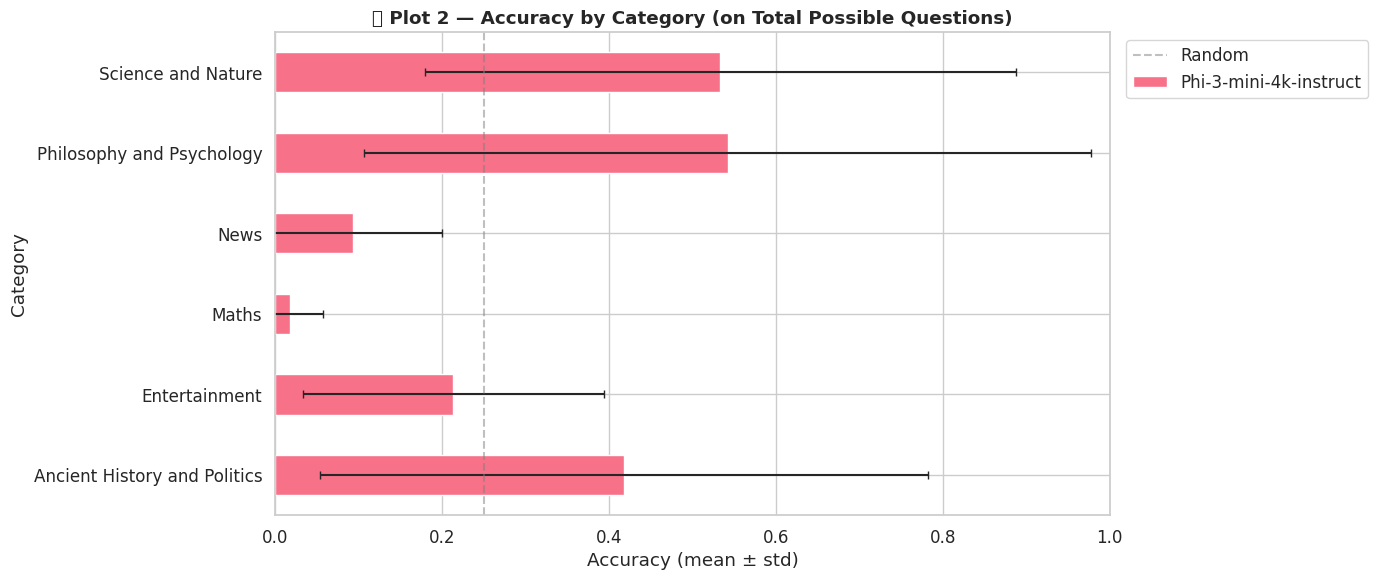

📊 Saved → /content/drive/MyDrive/NLP/plots/01b_accuracy_by_model_total.png


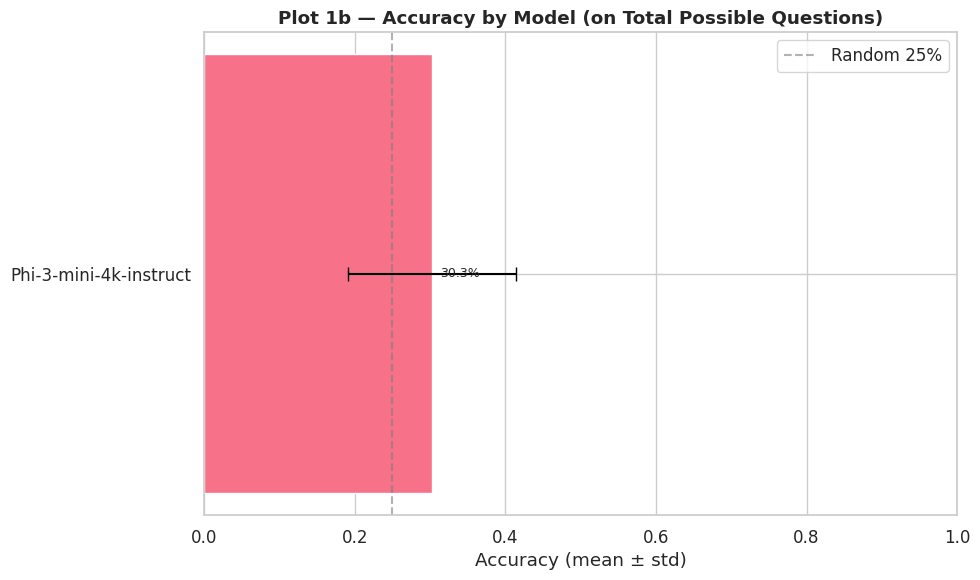

/tmp/ipykernel_19475/2520525152.py:446: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "14_response_time")
/tmp/ipykernel_19475/2520525152.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/plots/14_response_time.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


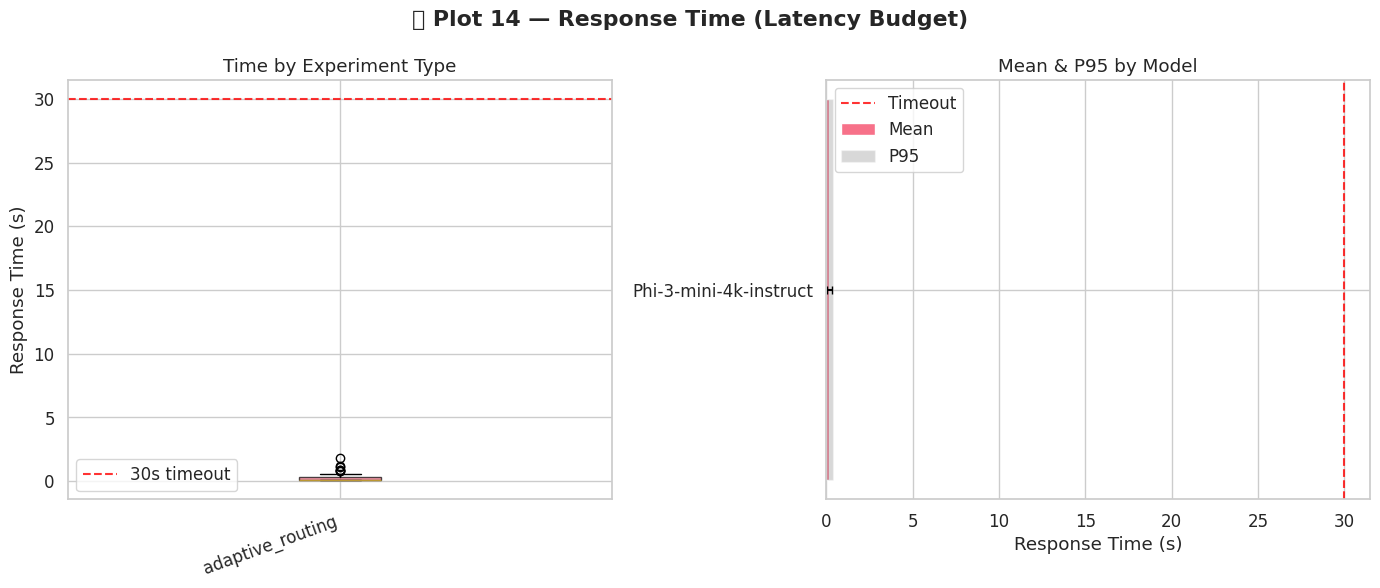

In [ ]:
df_adaptive= load_runs(*[p for p in RUNS_DIR.glob("run_*_adaptive_routing_*.json")])

plot_accuracy_by_category(df_adaptive)
plot_accuracy_by_model_total(df_adaptive)
plot_response_time(df_adaptive)

### Audio implementation with ACSR

In [ ]:
# Same model & prompt as experiment 6
AUDIO_N_RUNS = 5

for i in range(AUDIO_N_RUNS):
    print(f"\n{'='*60}")
    print(f"  Audio Run {i+1}/{AUDIO_N_RUNS}")
    print(f"{'='*60}")
    meta_audio = {
        "experiment_type": "audio_mode",
        "model_name":      BEST_MODEL_NAME,
        "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
        "quantization":    "none",
        "prompt_type":     BEST_PROMPT,
        "enable_thinking": False,
        "rag_used":        True,
        "tool_used":       True,
        "fine_tuned":      False,
        "notes":           "Audio mode: Whisper transcription + ASR clearing via qwen3.5:0.8b",
    }
    play_game_audio(
        client=client,
        llm_pipeline=pipeline_best,
        run_metadata=meta_audio,
        output_dir=OUTPUT_DIR,
        enable_rag=True,
        enable_tools=True,
        use_category_routing=True,
    )


  Audio Run 1/5
───────────────────────────────────────────────────────
  Entertainment  [AUDIO MODE]
───────────────────────────────────────────────────────
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): What is the primary principle behind Denzel Washington's acting style?
  A (raw+regex): Option A: natural charm and emotional intensity
  B (raw+regex): Option B: If this is on physical stunts!
  C (raw+regex): Option C: focusing on comedy
  D (raw+regex): Option D: use of Special Effects
  [role_playing] A=0.99 B=0.01 C=0.00 D=0.00 choosen:[A] conf=98.8%  (0.1s)
Q 1 |[A] conf=98.8% |0.1s
correct answer
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): Which of the following best describes the relationship between Brian Jones and the other band members in the e

/usr/local/lib/python3.12/dist-packages/wikipedia/wikipedia.py:389: GuessedAtParserWarning: No parser was explicitly specified, so I'm using the best available HTML parser for this system ("lxml"). This usually isn't a problem, but if you run this code on another system, or in a different virtual environment, it may use a different parser and behave differently.

The code that caused this warning is on line 389 of the file /usr/local/lib/python3.12/dist-packages/wikipedia/wikipedia.py. To get rid of this warning, pass the additional argument 'features="lxml"' to the BeautifulSoup constructor.

  lis = BeautifulSoup(html).find_all('li')


  [role_playing] A=0.98 B=0.00 C=0.01 D=0.00 choosen:[A] conf=98.5%  (0.1s)
Q 5 |[A] conf=98.5% |0.1s
correct answer
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): Which of the following best describes the relationship between Mick Jagger and Keith Richard?
  A (raw+regex): Option A: they were brothers
  B (raw+regex): Option B: They were close friends and primary songwriting partners
  C (raw+regex): Option C: they had a long standing professional rivalry
  D (raw+regex): Option D: e! They were distant and rarely collaborated
  [role_playing] A=0.00 B=1.00 C=0.00 D=0.00 choosen:[B] conf=99.7%  (0.1s)
Q 6 |[B] conf=99.7% |0.1s
correct answer
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): What is the primary reason for the film Titanic success? According to Jam

✅ DataFrame: 168 rows from 10 run(s)
✅ DataFrame: 678 rows from 20 run(s)

📊 Audio runs: 168 questions, Text runs: 678 questions


/tmp/ipykernel_25198/2520525152.py:485: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  run_acc = df.groupby(['model_name','run_id']).apply(
/tmp/ipykernel_25198/2520525152.py:485: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  run_acc = df.groupby(['model_name','run_id']).apply(


📊 Saved → /content/drive/MyDrive/NLP/plots/16a_audio_vs_text_accuracy.png


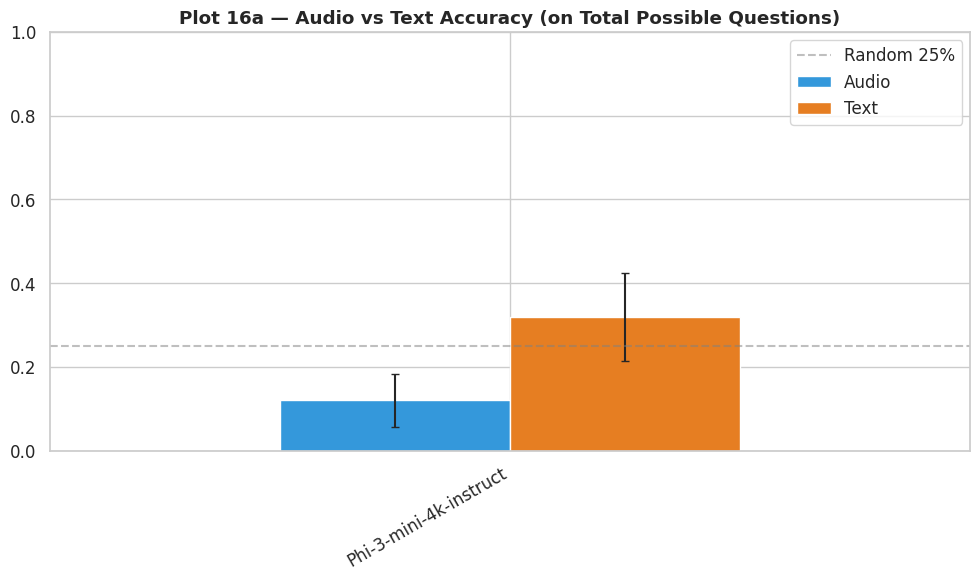

📊 Saved → /content/drive/MyDrive/NLP/plots/16b_audio_vs_text_by_category.png


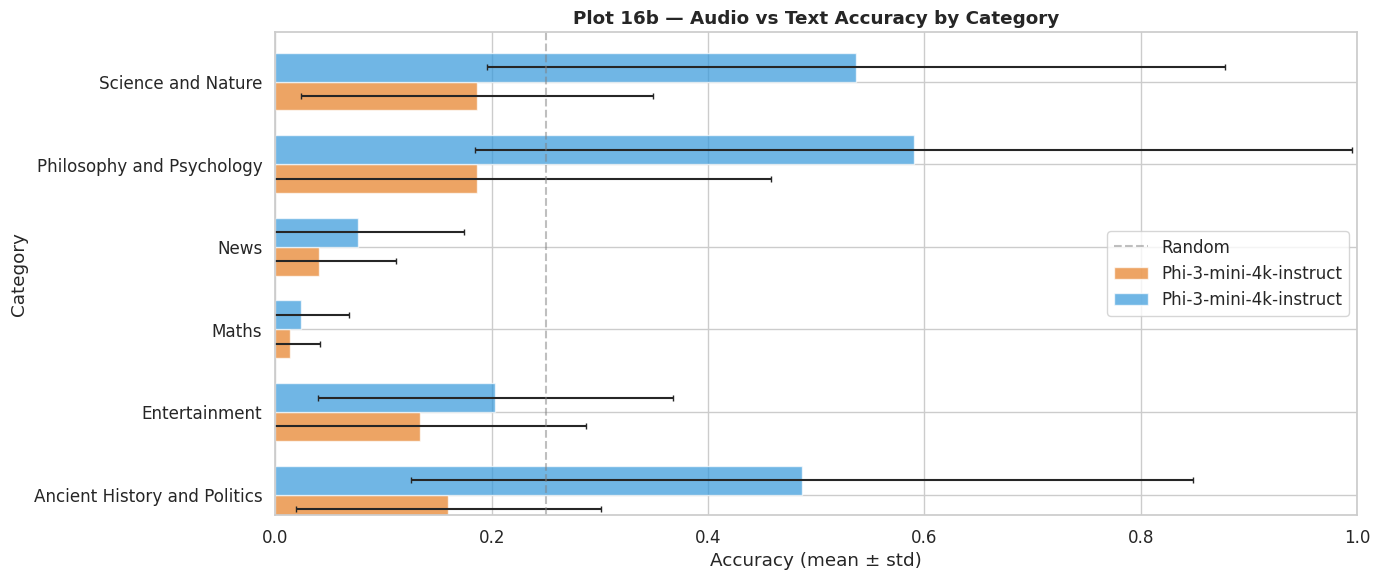

In [13]:
df_audio_runs = load_runs(*[p for p in RUNS_DIR.glob("run_*_audio_mode_*.json")])
df_text_runs  = load_runs(*[p for p in RUNS_DIR.glob("run_*_adaptive_routing_*.json")])

if not df_audio_runs.empty and not df_text_runs.empty:
    print(f"\n📊 Audio runs: {len(df_audio_runs)} questions, Text runs: {len(df_text_runs)} questions")
    plot_audio_vs_text_accuracy(df_text_runs, df_audio_runs)
else:
    print("⚠️  Missing audio or text run data for comparison plots.")

## Conclusion
The audio comes with a lot of random words that destroy the total performance, using a model to clean it up proved to be a losing strategy, using a regex worked much better since most of the distorsions were repetitive and easy to find